In [1]:
!pip install ucimlrepo -q

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch Bank Marketing dataset from UCI
bank = fetch_ucirepo(id=222)

# Combine inputs and target
df = pd.concat(
    [bank.data.features, bank.data.targets],
    axis=1
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (45211, 17)


In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (45211, 17)

Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Missing Values:
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64


In [5]:
# Convert Yes/No into numbers
df["Subscribed"] = df["y"].map({
    "no": 0,
    "yes": 1
})

print(df[["y", "Subscribed"]].head())

    y  Subscribed
0  no           0
1  no           0
2  no           0
3  no           0
4  no           0


In [6]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y,Subscribed
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no,0
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no,0
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no,0
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no,0


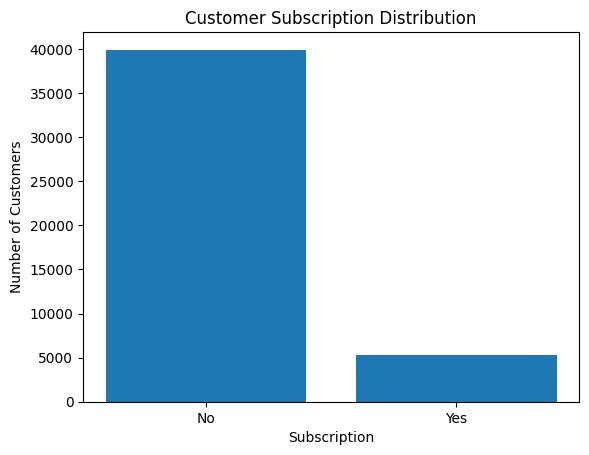

Subscribed
0    39922
1     5289
Name: count, dtype: int64


In [7]:
import matplotlib.pyplot as plt

counts = df["Subscribed"].value_counts().sort_index()

plt.bar(["No", "Yes"], counts)

plt.title("Customer Subscription Distribution")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

print(counts)

In [8]:
features = [
    "age",
    "job",
    "marital",
    "education",
    "balance",
    "housing",
    "loan",
    "campaign",
    "previous"
]

X = df[features]
y = df["Subscribed"]

print(X.head())
print(y.head())

   age           job  marital  education  balance housing loan  campaign  \
0   58    management  married   tertiary     2143     yes   no         1   
1   44    technician   single  secondary       29     yes   no         1   
2   33  entrepreneur  married  secondary        2     yes  yes         1   
3   47   blue-collar  married        NaN     1506     yes   no         1   
4   33           NaN   single        NaN        1      no   no         1   

   previous  
0         0  
1         0  
2         0  
3         0  
4         0  
0    0
1    0
2    0
3    0
4    0
Name: Subscribed, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 36168
Testing samples: 9043


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_columns = [
    "job",
    "marital",
    "education",
    "housing",
    "loan"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [13]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 88.29 %


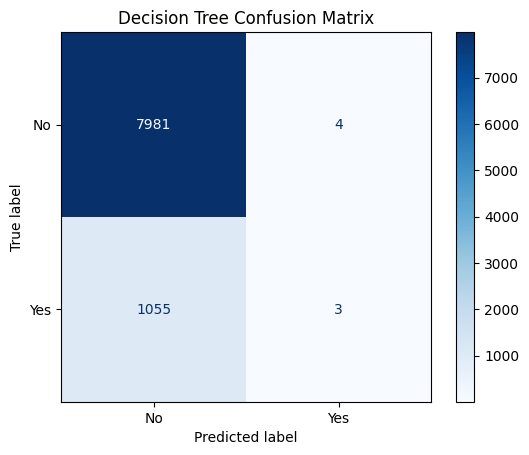

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

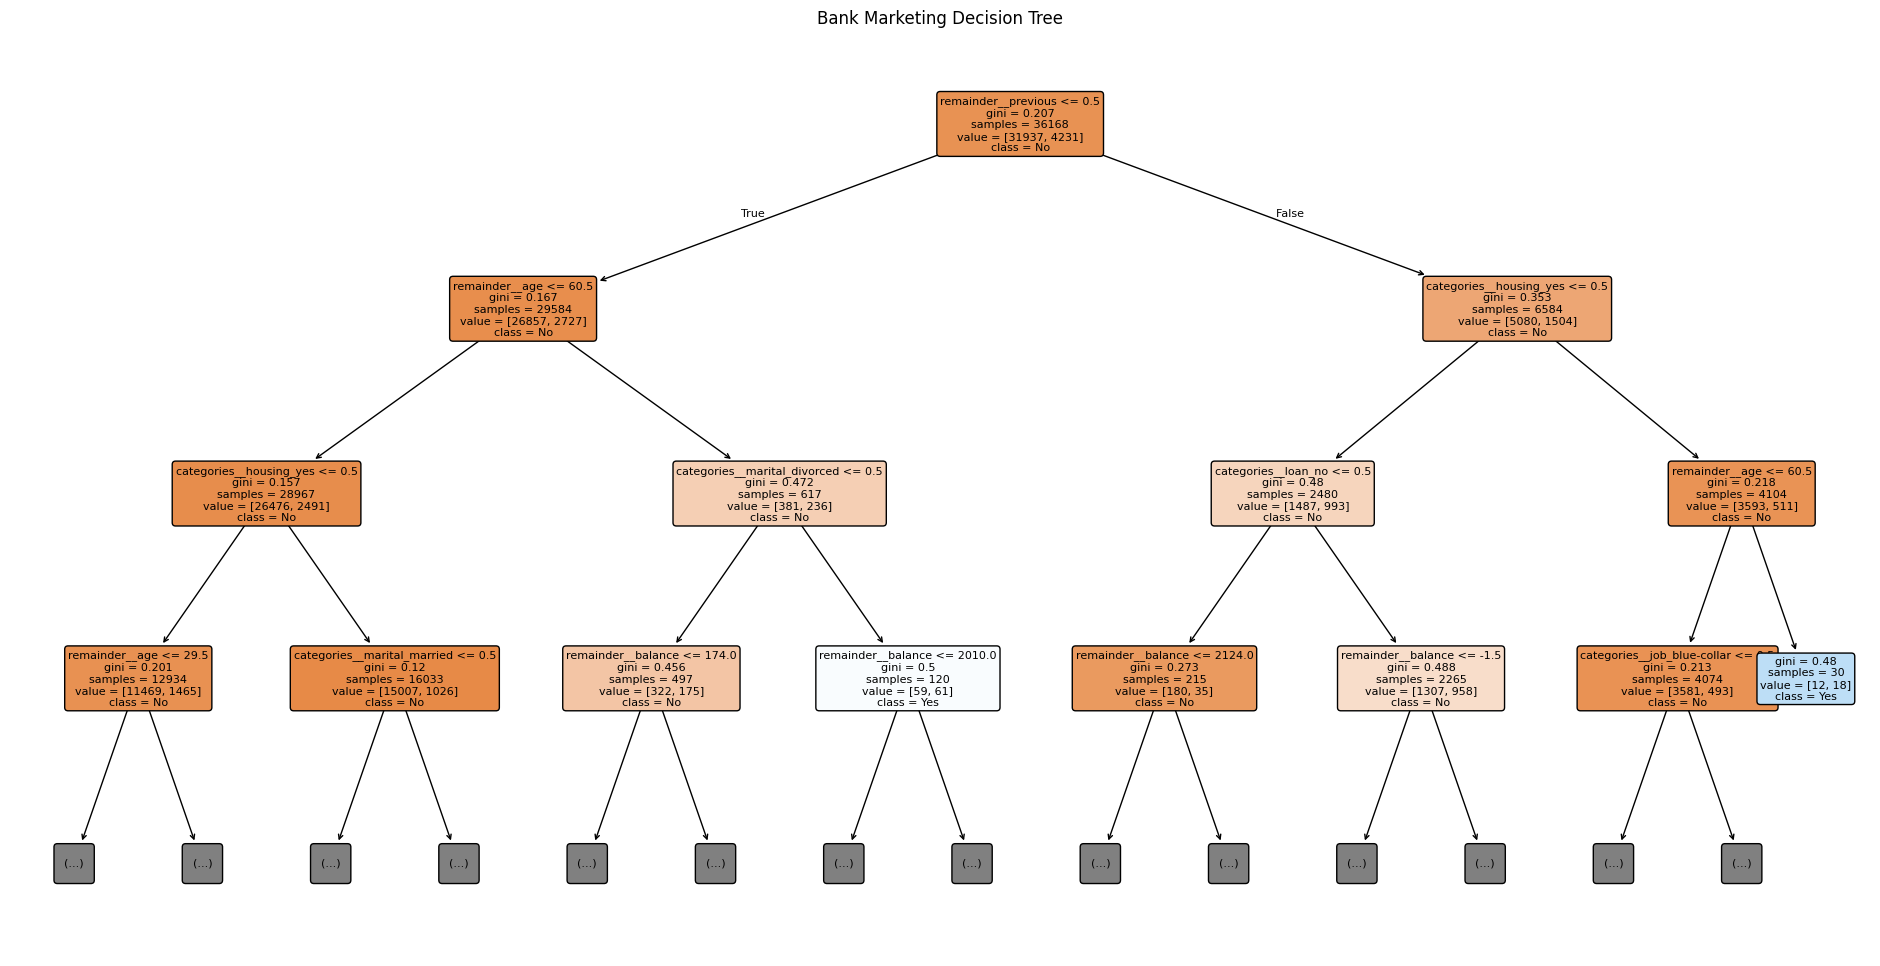

In [16]:
from sklearn.tree import plot_tree

# Get trained classifier

tree_model = model.named_steps["classifier"]

# Get feature names after encoding

feature_names = model.named_steps[

    "preprocessing"

].get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(

    tree_model,

    feature_names=feature_names,

    class_names=["No", "Yes"],

    filled=True,

    rounded=True,

    fontsize=8,

    max_depth=3

)

plt.title("Bank Marketing Decision Tree")

plt.show()


In [17]:
df.to_csv(
    "bank_marketing_dataset.csv",
    index=False
)

print("CSV saved successfully!")

CSV saved successfully!
